In [51]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import joblib 

In [2]:
df = pd.read_csv("ChatGPT sentiment analysis.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 219294 entries, 0 to 219293
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  219294 non-null  int64 
 1   tweets      219294 non-null  object
 2   labels      219294 non-null  object
dtypes: int64(1), object(2)
memory usage: 5.0+ MB


In [3]:
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

In [4]:
# check missing value 
print(df.isnull().sum())

tweets    0
labels    0
dtype: int64


In [6]:
df.dtypes

tweets    object
labels    object
dtype: object

In [7]:

print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 1671


In [9]:
df.drop_duplicates(inplace= True )

In [10]:
# Prepare data

In [11]:
# Remove rows with missing target labels
df = df.dropna(subset=["labels"]).copy()


In [12]:
# Replace missing tweets with empty strings
df["tweets"] = df["tweets"].fillna("").astype(str)


In [13]:
# Remove rows with empty tweets
df = df[df["tweets"].str.strip() != ""].copy()

In [14]:
print("\nFinal dataset shape:", df.shape)


Final dataset shape: (217623, 2)


In [15]:
print(df["labels"].value_counts())

labels
bad        106695
good        55754
neutral     55174
Name: count, dtype: int64


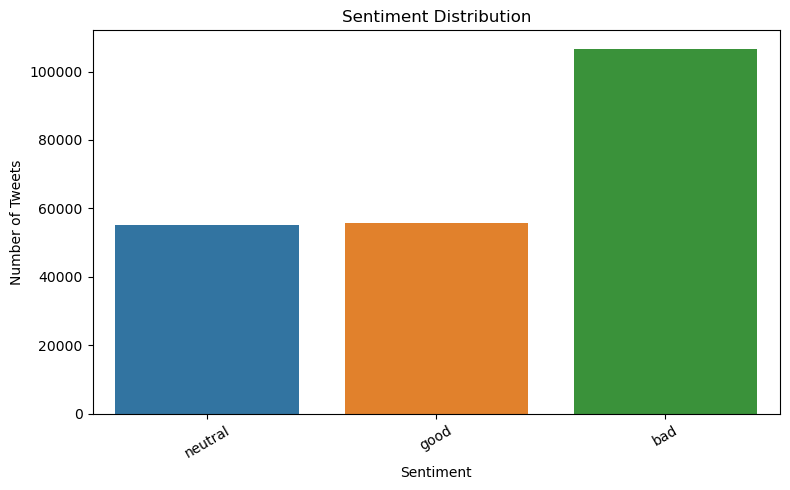

In [20]:
# CELL 6: Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="labels")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [21]:
 # CELL 7: Text preprocessing


In [22]:
from nltk.corpus import stopwords
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Download stopwords
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nitis\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [23]:
stop_word = set(stopwords.words("english"))


In [24]:
# Keep negation words because they can change sentiment
stop_word.difference_update({"not", "no", "nor", "never"})

In [25]:
def clean_text(text):
    text = str(text).lower()
    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    # Remove usernames
    text = re.sub(r"@\w+", " ", text)
    # Remove hashtag symbol but keep the word
    text = text.replace("#", "")
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)
    # Keep letters and numbers; replace other characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    tokens = text.split()

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_word
    ]

    return " ".join(tokens)

In [26]:
df["clean_tweets"] = df["tweets"].apply(clean_text)

In [27]:
print(df[["tweets", "clean_tweets", "labels"]].head())


                                              tweets  \
0  ChatGPT: Optimizing Language Models for Dialog...   
1  Try talking with ChatGPT, our new AI system wh...   
2  ChatGPT: Optimizing Language Models for Dialog...   
3  THRILLED to share that ChatGPT, our new model ...   
4  As of 2 minutes ago, @OpenAI released their ne...   

                                        clean_tweets   labels  
0        chatgpt optimizing language models dialogue  neutral  
1  try talking chatgpt new ai system optimized di...     good  
2  chatgpt optimizing language models dialogue ai...  neutral  
3  thrilled share chatgpt new model optimized dia...     good  
4  2 minutes ago released new chatgpt n nand use ...      bad  


In [28]:
X = df["clean_tweets"]
y = df["labels"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (217623,)
Target shape: (217623,)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 174098
Testing samples: 43525


In [30]:
# CELL 10: Convert text into numerical features using TF-IDF

In [31]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

In [32]:
# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the learned vocabulary to test data
X_test_tfidf = tfidf.transform(X_test)

In [33]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [34]:
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [35]:
lr_pred = lr_model.predict(X_test_tfidf)

In [36]:
lr_accuracy = accuracy_score(y_test, lr_pred)

In [37]:
lr_macro_f1 = f1_score(
    y_test,
    lr_pred,
    average="macro"
)

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Logistic Regression Macro F1:", round(lr_macro_f1, 4))

Logistic Regression Accuracy: 0.8527
Logistic Regression Macro F1: 0.8327


In [38]:
print(classification_report(y_test, lr_pred, zero_division=0))

              precision    recall  f1-score   support

         bad       0.93      0.91      0.92     21339
        good       0.84      0.83      0.84     11151
     neutral       0.73      0.75      0.74     11035

    accuracy                           0.85     43525
   macro avg       0.83      0.83      0.83     43525
weighted avg       0.85      0.85      0.85     43525



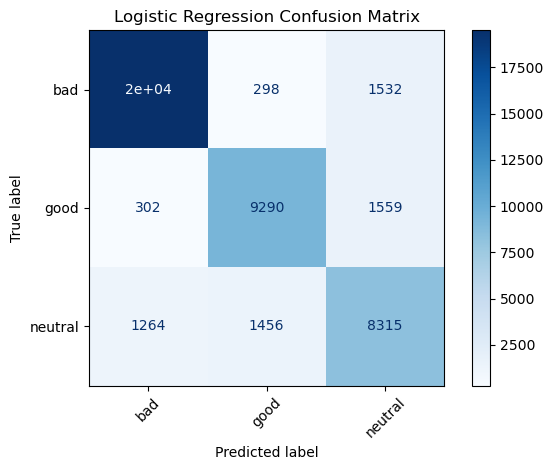

In [39]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [40]:
# Train Naive Bayes


In [41]:
nb_model = MultinomialNB()

In [42]:
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [43]:
nb_pred = nb_model.predict(X_test_tfidf)

In [44]:
nb_accuracy = accuracy_score(y_test, nb_pred)

In [45]:
nb_macro_f1 = f1_score(
    y_test,
    nb_pred,
    average="macro"
)

print("Naive Bayes Accuracy:", round(nb_accuracy, 4))
print("Naive Bayes Macro F1:", round(nb_macro_f1, 4))

print("\nNaive Bayes Classification Report:")
print(classification_report(y_test, nb_pred, zero_division=0))

Naive Bayes Accuracy: 0.7333
Naive Bayes Macro F1: 0.6715

Naive Bayes Classification Report:
              precision    recall  f1-score   support

         bad       0.77      0.94      0.84     21339
        good       0.71      0.71      0.71     11151
     neutral       0.64      0.36      0.46     11035

    accuracy                           0.73     43525
   macro avg       0.70      0.67      0.67     43525
weighted avg       0.72      0.73      0.71     43525



In [46]:
 # Compare both models
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "Accuracy": [lr_accuracy, nb_accuracy],
    "Macro F1": [lr_macro_f1, nb_macro_f1]
})

print(comparison)

                 Model  Accuracy  Macro F1
0  Logistic Regression  0.852705  0.832704
1          Naive Bayes  0.733326  0.671549


<Axes: xlabel='Model'>

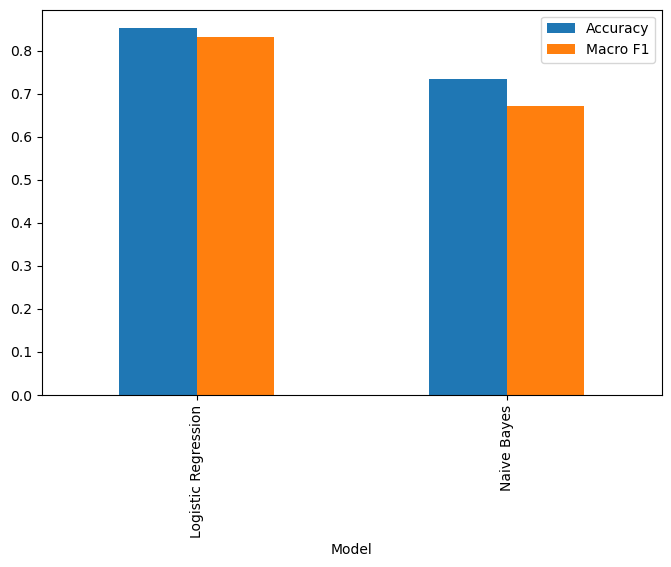

In [47]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5)
)


In [49]:
def predict_sentiment(text):
    cleaned_text = clean_text(text)

    # Use the same TF-IDF vectorizer used during training
    text_vector = tfidf.transform([cleaned_text])

    # Predict using Logistic Regression
    prediction = lr_model.predict(text_vector)[0]

    print("Original text:", text)
    print("Cleaned text:", cleaned_text)
    print("Predicted sentiment:", prediction)
    
    probabilities = lr_model.predict_proba(text_vector)[0]

    print("\nClass probabilities:")

    for label, probability in zip(
        lr_model.classes_,
        probabilities
    ):
        print(f"{label}: {probability:.4f}")

In [50]:
predict_sentiment("ChatGPT is amazing and very helpful!")

predict_sentiment("ChatGPT gives terrible answers.")

predict_sentiment("ChatGPT is an AI chatbot.")


Original text: ChatGPT is amazing and very helpful!
Cleaned text: chatgpt amazing helpful
Predicted sentiment: good

Class probabilities:
bad: 0.0000
good: 0.9975
neutral: 0.0025
Original text: ChatGPT gives terrible answers.
Cleaned text: chatgpt gives terrible answers
Predicted sentiment: bad

Class probabilities:
bad: 0.9831
good: 0.0002
neutral: 0.0167
Original text: ChatGPT is an AI chatbot.
Cleaned text: chatgpt ai chatbot
Predicted sentiment: bad

Class probabilities:
bad: 0.9266
good: 0.0013
neutral: 0.0720


In [52]:
joblib.dump(lr_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


In [53]:
# Load the saved model and make a prediction
loaded_model = joblib.load("sentiment_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")


In [54]:
def predict_with_saved_model(text):
    cleaned_text = clean_text(text)
    text_vector = loaded_tfidf.transform([cleaned_text])

    prediction = loaded_model.predict(text_vector)[0]

    return prediction

In [55]:
print(
    predict_with_saved_model(
        "I really enjoy using ChatGPT"
    )
)


neutral
